## Hardware & Environment Sanity Check

In [1]:
import os
import time
import cv2
import matplotlib.pyplot as plt
import pandas as pd
import torch
from ultralytics import YOLO

# 1. Device check
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print(f"Using compute device: {device}")

# 2. Path definitions based on your project structure
PROJECT_ROOT = os.path.abspath("..")
MODEL_PATH = os.path.join(PROJECT_ROOT, "notebooks", "yolov8n-seg.pt")
IMAGE_DIR = os.path.join(PROJECT_ROOT, "v1.0-mini", "samples", "CAM_FRONT")
OUTPUT_DIR = os.path.join(PROJECT_ROOT, "outputs", "seg_results")
EXCEL_PATH = os.path.join(PROJECT_ROOT, "notebooks", "experiment_results.xlsx")

# Verify directory existence
print(f"Sample images folder exists: {os.path.exists(IMAGE_DIR)}")

Using compute device: mps
Sample images folder exists: True


## Run Inference, Display Results, & Save Image Output

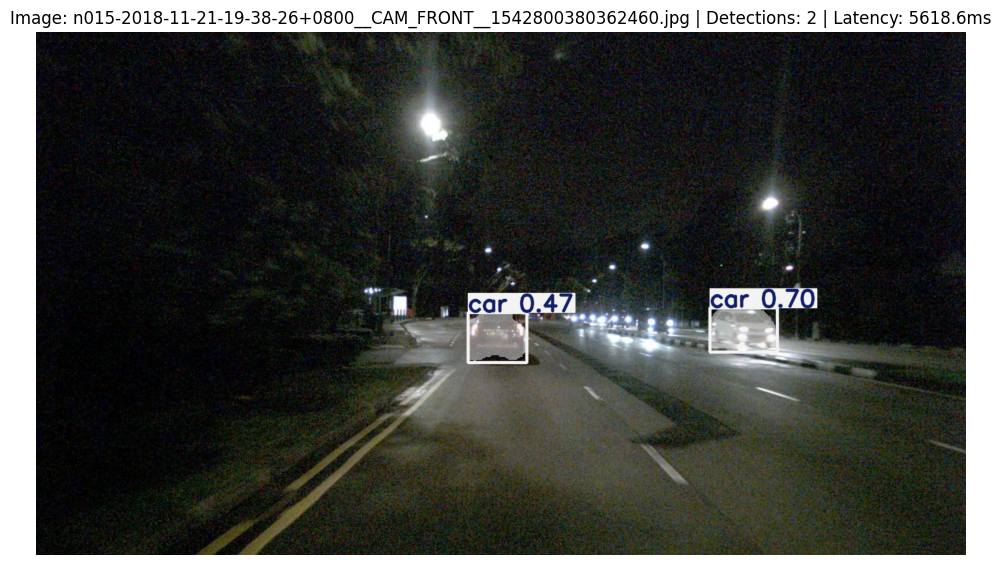

Saved segmentation visual to: /Users/anupamahalder/Autonomous_Vehicle_Risk_Estimation_Analysis/outputs/seg_results/seg_n015-2018-11-21-19-38-26+0800__CAM_FRONT__1542800380362460.jpg


In [2]:
# Pick the first front-camera image from nuScenes mini
sample_images = [
    f
    for f in os.listdir(IMAGE_DIR)
    if f.endswith(".jpg") or f.endswith(".png")
]

if len(sample_images) == 0:
    print("No images found in CAM_FRONT folder!")
else:
    img_name = sample_images[0]
    img_path = os.path.join(IMAGE_DIR, img_name)

    # Measure inference speed
    model = YOLO(MODEL_PATH)
    start_time = time.time()
    results = model.predict(source=img_path, device=device, verbose=False)
    inference_time_ms = (time.time() - start_time) * 1000

    # Extract detected objects count
    boxes = results[0].boxes
    detected_count = len(boxes) if boxes is not None else 0

    # Render prediction visual
    res_plotted = results[0].plot()
    res_rgb = cv2.cvtColor(res_plotted, cv2.COLOR_BGR2RGB)

    # Display image directly in the notebook cell
    plt.figure(figsize=(12, 7))
    plt.imshow(res_rgb)
    plt.title(
        f"Image: {img_name} | Detections: {detected_count} | Latency: {inference_time_ms:.1f}ms"
    )
    plt.axis("off")
    plt.show()

    # Save output visualization to outputs/seg_results/
    out_img_path = os.path.join(OUTPUT_DIR, f"seg_{img_name}")
    cv2.imwrite(out_img_path, res_plotted)
    print(f"Saved segmentation visual to: {out_img_path}")

## Log Metrics into experiment_results.xlsx

In [3]:
# Log metrics to Excel
exp_data = {
    "Exp_ID": [f"EXP_SEG_{int(time.time())}"],
    "Timestamp": [time.strftime("%Y-%m-%d %H:%M:%S")],
    "Task": ["Instance Segmentation"],
    "Model": ["YOLOv8n-seg"],
    "Sample_Image": [img_name],
    "Objects_Detected": [detected_count],
    "Inference_Time_ms": [round(inference_time_ms, 2)],
    "Device": [str(device)],
}

df_new = pd.DataFrame(exp_data)

if os.path.exists(EXCEL_PATH):
    df_existing = pd.read_excel(EXCEL_PATH)
    df_final = pd.concat([df_existing, df_new], ignore_index=True)
else:
    df_final = df_new

df_final.to_excel(EXCEL_PATH, index=False)
print(f"Successfully logged experiment entry to:\n{EXCEL_PATH}")

# Show current Excel table directly in notebook output
df_final.tail(5)

Successfully logged experiment entry to:
/Users/anupamahalder/Autonomous_Vehicle_Risk_Estimation_Analysis/notebooks/experiment_results.xlsx


,Exp_ID,Task,Model,Device,Status,Timestamp,Sample_Image,Objects_Detected,Inference_Time_ms
0,EXP_001,Segmentation,YOLOv8n-seg,mps,Success,NaN,NaN,NaN,NaN
1,EXP_SEG_1788600916,Instance Segmentation,YOLOv8n-seg,mps,NaN,2026-09-05 15:05:16,n015-2018-11-21-19-38-26+0800__CAM_FRONT__1542...,2.0,5618.59
